## Notebook 3: MLP through the frozen pipeline

**Owner:** Person 3. **Model:** one-hidden-layer MLP (`MLPClassifier`, 256 units, early stopping). CPU only.

This notebook runs the MLP slice of the experiment grid through the shared core (`core.py`, built by Notebook 0), plus the two jobs the plan gives the MLP owner: the **regularization and augmentation sweep**, and (added here) a **harder blind-detection test**, since the 10-task version saturates for every method.

Order of work, following the freeze protocol:

| Part | What | Touches OOD data? |
|---|---|---|
| 1 | Load the shared core and E1 data | no |
| 2 | Sanity checks: MLP regularization on E1 validation; counterfactual realism check | no |
| 3 | Smoke test of the MLP path | no |
| 4 | Main grid (40 runs) → **freeze** | no |
| 5 | Blind detection, 10 tasks, all six scores | no |
| 6 | Regularization × augmentation sweep → **separate freeze** | no |
| 7 | Exploratory: first-layer weight mass by input region | no |
| 8 | OOD evaluation + Spearman analysis (main grid and sweep), within-level analysis | **yes, only after both freezes verify** |
| 9 | Hard blind detection (close shortcut strengths; ground truth from actual damage) | yes, after scores are computed |
| 10 | Hand-off | |

**Kaggle setup:** Internet **on** (MNIST download). No GPU needed. Run as a committed version: **Save Version → Save & Run All**. Expected run time on Kaggle CPU is roughly 1.5 to 2 hours; the slowest parts are the main grid and the 10 blind-detection tasks, which train on all 48,000 E1 images.

Everything is written to `/kaggle/working/results/mlp/`, mirroring `results/lr` and `results/cnn`.

## Part 1: shared core and E1 data

The first cell is the **unchanged** `core.py` from Notebook 0, the same copy embedded in Notebook 1. Do not edit it: the next cell prints its SHA-256, which must match the other model notebooks, otherwise results cannot be pooled.

In [1]:
# Embedded copy of Notebook 0's core.py. It is written to disk only if no usable core.py is attached.
CORE_EMBEDDED = r'''
import os, json, time, hashlib, itertools, pickle, shutil, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, t as t_dist
from itertools import combinations
from math import factorial
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, mutual_info_score
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
# Data globals (set by load_data). Scoring notebooks call load_data(include_test=False),
# so test_x / test_y stay None and OOD data is mechanically unavailable before the freeze.
train_x = train_y = val_x = val_y = test_x = test_y = None

def load_data(root=None, include_test=False, seed=SEED):
    """Load binary (even/odd) MNIST with the same 80/20 train/val split as Notebook 0."""
    global train_x, train_y, val_x, val_y, test_x, test_y
    import glob
    from torchvision import datasets
    cands = [root] if root else []
    cands += ["/kaggle/working/data", *sorted(glob.glob("/kaggle/input/*/data")),
              *sorted(glob.glob("/kaggle/input/*/*/data")), "./data"]
    found = next((c for c in cands if c and os.path.isdir(os.path.join(c, "MNIST", "raw"))), None)
    download = found is None
    root = found or (root or "/kaggle/working/data")
    tr = datasets.MNIST(root=root, train=True, download=download)
    xa, ya = tr.data.numpy(), (tr.targets.numpy() % 2).astype(np.int64)
    idx = np.random.default_rng(seed).permutation(len(xa))
    cut = int(0.8 * len(idx))
    train_x, train_y = xa[idx[:cut]], ya[idx[:cut]]
    val_x, val_y = xa[idx[cut:]], ya[idx[cut:]]
    if include_test:
        te = datasets.MNIST(root=root, train=False, download=download)
        test_x, test_y = te.data.numpy(), (te.targets.numpy() % 2).astype(np.int64)
    else:
        test_x = test_y = None
    return {"train": len(train_x), "val": len(val_x), "test": None if test_x is None else len(test_x)}


# ===== data generator =====
ATTRS = ["color", "marker_tl", "marker_br"]
PATCH = {"marker_tl": (slice(1, 4), slice(1, 4)),     # top-left 3x3
         "marker_br": (slice(24, 27), slice(24, 27))} # bottom-right 3x3

def make_multi_attr_mnist(images, labels, corrs, seed=0):
    """corrs: dict attr -> label correlation (0 = independent decoy)."""
    rng = np.random.default_rng(seed)
    gray = images.astype(np.float32) / 255.0
    n = len(labels)
    out = np.zeros((n, 3, 28, 28), dtype=np.float32)
    attrs = {}
    for a in ATTRS:
        c = corrs.get(a, 0.0)
        match = rng.random(n) < (1 + c) / 2
        attrs[a] = np.where(match, labels, 1 - labels).astype(np.int64)
    out[attrs["color"] == 0, 0] = gray[attrs["color"] == 0]   # red
    out[attrs["color"] == 1, 1] = gray[attrs["color"] == 1]   # green
    for a, (r, c) in PATCH.items():                           # markers: blue channel only
        out[attrs[a] == 1, 2, r, c] = 1.0
    return out, attrs


# ===== interventions =====
def intervene(images, attr):
    x = images.copy()
    if attr == "color":
        x[:, [0, 1]] = images[:, [1, 0]]                 # swap red/green
    elif attr in PATCH:
        r, c = PATCH[attr]
        x[:, 2, r, c] = 1.0 - images[:, 2, r, c]         # toggle marker on/off
    elif attr == "null":
        pass                                             # do-nothing control
    else:
        raise ValueError(attr)
    return x


# ===== registry =====
def build_registry(labels, attrs, threshold=0.5, design_corrs=None):
    """
    Register spuriousness from the experiment design, not noisy sample correlation.
    Convention: strictly greater than threshold is spurious; exactly threshold is not.
    Observed sample correlations are retained as diagnostics.
    """
    reg = {}
    for a, v in attrs.items():
        observed = float(np.corrcoef(labels, v)[0, 1])
        designed = float(design_corrs[a]) if design_corrs is not None and a in design_corrs else observed
        reg[a] = {
            "train_corr": observed,
            "design_corr": designed,
            "spurious": abs(designed) > threshold
        }
    return reg

flat = lambda x: x.reshape(len(x), -1)


# ===== scores =====
def sensitivity_score(model, X, attr):
    """Main score (Person 2's job): fraction of predictions that flip."""
    p0 = model.predict(flat(X))
    p1 = model.predict(flat(intervene(X, attr)))
    return float(np.mean(p0 != p1))

def label_corr_score(labels, attrs, attr):
    """Data-only baseline."""
    return abs(float(np.corrcoef(labels, attrs[attr])[0, 1]))

def mutual_information_score(labels, attrs, attr):
    """Data-only baseline: mutual information between training labels and a
    training attribute (discrete, computed on E1 training data)."""
    return float(mutual_info_score(np.asarray(labels).astype(int),
                                   np.asarray(attrs[attr]).astype(int)))

def grouped_attribute_permutation_score(model, X, y, attr_values, attr,
                                        n_repeats=5, seed=12345):
    """Grouped permutation importance on held-out validation data.
    Shuffle one attribute across examples, rebuild that attribute in the images,
    and measure the accuracy drop.  Score = baseline acc - mean permuted acc.
    (Different from intervene(), which toggles the attribute within each example.)"""
    X = np.asarray(X); y = np.asarray(y)
    current = np.asarray(attr_values).astype(np.int64)
    if not (len(X) == len(y) == len(current)):
        raise ValueError("X, y and attr_values must have equal lengths.")
    if attr != "color" and attr not in PATCH:
        raise ValueError(f"Unknown attribute: {attr}")
    baseline_acc = accuracy_score(y, model.predict(flat(X)))
    rng = np.random.default_rng(seed)
    drops = []
    for _ in range(n_repeats):
        shuffled = rng.permutation(current)
        X_perm = X.copy()
        if attr == "color":
            changed = shuffled != current            # swap R/G only where assigned colour changed
            X_perm[changed, 0] = X[changed, 1]
            X_perm[changed, 1] = X[changed, 0]
        else:
            r, c = PATCH[attr]                       # rebuild marker from shuffled values
            X_perm[:, 2, r, c] = shuffled[:, None, None].astype(X_perm.dtype)
        drops.append(baseline_acc - accuracy_score(y, model.predict(flat(X_perm))))
    return float(np.mean(drops))


# ===== stability =====
def stability_score(model, X, y, attrs, attr):
    pred = model.predict(flat(X))
    agree = attrs[attr] == y
    if agree.sum() < 20 or (~agree).sum() < 20:
        return np.nan                     # too few samples in one group
    return float(accuracy_score(y[agree], pred[agree])
                 - accuracy_score(y[~agree], pred[~agree]))


# ===== shapley (SHAP-style) =====
def attribute_shapley(model, X, y, attr_list):
    k = len(attr_list)
    def value(S):
        x = X
        for a in S:
            x = intervene(x, a)
        proba = model.predict_proba(flat(x))
        return proba[np.arange(len(y)), y]          # P(true class)
    cache = {frozenset(S): value(S)
             for r in range(k + 1) for S in combinations(attr_list, r)}
    phi = {}
    for a in attr_list:
        others = [b for b in attr_list if b != a]
        tot = np.zeros(len(y))
        for r in range(k):
            w = factorial(r) * factorial(k - r - 1) / factorial(k)
            for S in combinations(others, r):
                tot += w * (cache[frozenset(S)] - cache[frozenset(S) | {a}])
        phi[a] = float(np.mean(np.abs(tot)))
    return phi


# ===== blind-detection helpers =====
def run_task(task_id, model_fn, n_score=2000):
    rng = np.random.default_rng(1000 + task_id)
    order = rng.permutation(ATTRS)
    corrs = {order[0]: 0.9, order[1]: 0.6, order[2]: 0.0}   # strong, weak, decoy

    Xtr, Atr = make_multi_attr_mnist(train_x, train_y, corrs, seed=2000 + task_id)
    Xva, Ava = make_multi_attr_mnist(val_x,   val_y,   corrs, seed=3000 + task_id)
    reg = build_registry(train_y, Atr, threshold=0.5, design_corrs=corrs)

    model = model_fn().fit(flat(Xtr), train_y)
    Xs, ys = Xva[:n_score], val_y[:n_score]
    As = {a: v[:n_score] for a, v in Ava.items()}
    shap = attribute_shapley(model, Xs, ys, ATTRS)

    rows = []
    for a in ATTRS:
        rows.append({
            "task": task_id, "attr": a, "true_corr": corrs[a],
            "spurious": reg[a]["spurious"],
            "sensitivity": sensitivity_score(model, Xs, a),
            "label_corr":  label_corr_score(train_y, Atr, a),
            "stability":   stability_score(model, Xs, ys, As, a),
            "shap":        shap[a],
            "mutual_info": mutual_information_score(train_y, Atr, a),
            "permutation_importance": grouped_attribute_permutation_score(
                model, Xs, ys, As[a], a, n_repeats=5, seed=12345),
        })
    null = sensitivity_score(model, Xs, "null")
    return rows, order[0], null

def evaluate(all_rows, strongest,
             methods=("sensitivity", "label_corr", "stability", "shap",
                      "mutual_info", "permutation_importance")):
    df = pd.DataFrame(all_rows)
    out = {}
    for m in methods:
        top1 = np.mean([df[df.task == t].sort_values(m, ascending=False).attr.iloc[0] == s
                        for t, s in strongest.items()])
        sub = df.dropna(subset=[m])
        auroc = roc_auc_score(sub.spurious, sub[m]) if sub.spurious.nunique() == 2 else np.nan
        out[m] = {"top1": top1, "auroc": auroc}
    return df, pd.DataFrame(out).T


# ===== config =====
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("./working")

CONFIG = {
    "out_dir": f"{WORK}/runs_mi_perm_v2",  # fresh dir: v1 used an intervention flip, not a true permutation
    # ---- experiment grid (cut down to what the team can finish) ----
    "grid": {
        "arch":       ["lr"],                    # Stage B: add "rf", "mlp", "cnn"
        "train_corr": [0.5, 0.7, 0.85, 0.95],
        "size":       [5000, 20000],
        "seed":       [0, 1, 2, 3, 4],
        "reg":        ["default"],               # stretch: ["low", "default", "high"]
        "aug":        ["none"],                  # stretch: ["none", "color_rand"]
    },
    "shortcut":    "color",                      # attribute whose correlation is swept
    "decoy_corrs": {"marker_tl": 0.0, "marker_br": 0.0},   # label-independent decoys
    "aug_p":       0.5,                          # fraction of train images colour-swapped under "color_rand"
    # ---- OOD environments (colour-label correlation at test time) ----
    "ood_envs":    {"E2": 0.75, "E3": 0.50, "E4": 0.25, "E5": 0.00, "REV": -0.95},
    # ---- scoring ----
    "n_score":     2000,                         # held-out val samples used for scoring
    "spurious_threshold": 0.5,
    "methods":     ["sensitivity", "label_corr", "stability", "shap",
                    "mutual_info", "permutation_importance"],
    # ---- analysis ----
    "target":      "rev_drop",                   # also: "mean_drop", "worst_drop"
    "cluster_by":  "seed",                       # cluster bootstrap unit
    "n_boot":      2000,
    "alpha":       0.05,
}

RESULT_COLS = ["run_id", "model", "seed", "size", "corr", "reg", "aug",
               "method", "feature", "score", "spurious"]

def read_scores(path):
    # keep the literal feature name "null" (pandas would otherwise read it as NaN)
    return pd.read_csv(path, keep_default_na=False, na_values=[""])

def paths(cfg):
    d = cfg["out_dir"]
    return {
        "dir": d,
        "models":   f"{d}/models",
        "partial":  f"{d}/partial",
        "meta":     f"{d}/run_meta.csv",
        "frozen":   f"{d}/scores_frozen.csv",
        "manifest": f"{d}/scores_frozen.manifest.json",
        "ood_long": f"{d}/ood_drops_long.csv",
        "ood_wide": f"{d}/ood_drops.csv",
        "analysis": f"{d}/analysis_spearman.csv",
    }

def grid_runs(cfg):
    g = cfg["grid"]
    keys = ["arch", "train_corr", "size", "seed", "reg", "aug"]
    return [dict(zip(keys, v)) for v in itertools.product(*[g[k] for k in keys])]

def run_id_of(r):
    return f"{r['arch']}_c{r['train_corr']}_n{r['size']}_s{r['seed']}_r{r['reg']}_a{r['aug']}"


# ===== model factory =====
# MODEL FACTORY 
# All models take FLAT inputs (N, 3*28*28) because the shared score functions call
# model.predict(flat(X)). A CNN wrapper (Stage B) must reshape inside and have
# fit / predict / predict_proba, then be added to MODEL_REGISTRY.
MODEL_REGISTRY = {}

REG_LEVELS = {
    "lr":  {"low": 10.0, "default": 1.0,  "high": 0.01},   # C
    "rf":  {"low": None, "default": 12,   "high": 6},      # max_depth
    "mlp": {"low": 1e-5, "default": 1e-4, "high": 1e-2},   # L2 alpha
}

def make_model(arch, reg="default", seed=0):
    if arch in MODEL_REGISTRY:
        return MODEL_REGISTRY[arch](reg=reg, seed=seed)
    if arch == "lr":
        return LogisticRegression(C=REG_LEVELS["lr"][reg], max_iter=300)
    if arch == "rf":
        return RandomForestClassifier(n_estimators=200, max_depth=REG_LEVELS["rf"][reg],
                                      n_jobs=-1, random_state=seed)
    if arch == "mlp":
        return MLPClassifier(hidden_layer_sizes=(256,), alpha=REG_LEVELS["mlp"][reg],
                             max_iter=50, early_stopping=True, random_state=seed)
    raise ValueError(f"Unknown arch '{arch}'. Register it in MODEL_REGISTRY.")


# ===== run driver =====
# RUN DRIVER (pre-shift only: never touches test_x)
def _shap_cached(ctx, attr):
    if "_shap" not in ctx:
        ctx["_shap"] = attribute_shapley(ctx["model"], ctx["Xs"], ctx["ys"], ATTRS)
    return ctx["_shap"][attr]

# Every score method has the same shape: fn(ctx, attr) -> number.
# To add a new method (e.g. mutual information), just add it here.
SCORE_FNS = {
    "sensitivity": lambda ctx, a: sensitivity_score(ctx["model"], ctx["Xs"], a),
    "label_corr":  lambda ctx, a: label_corr_score(ctx["ytr"], ctx["Atr"], a),
    "stability":   lambda ctx, a: stability_score(ctx["model"], ctx["Xs"], ctx["ys"], ctx["As"], a),
    "shap":        _shap_cached,
    "mutual_info": lambda ctx, a: mutual_information_score(ctx["ytr"], ctx["Atr"], a),
    "permutation_importance": lambda ctx, a: grouped_attribute_permutation_score(
        ctx["model"], ctx["Xs"], ctx["ys"], ctx["As"][a], a,
        n_repeats=5, seed=12345),
}

def make_e1(cfg, train_corr, size, seed, aug):
    """Training environment E1 (+ held-out val). Uses train_x / val_x only."""
    corrs = {cfg["shortcut"]: train_corr, **cfg["decoy_corrs"]}
    rng = np.random.default_rng(10_000 + seed)
    idx = rng.choice(len(train_y), size=min(size, len(train_y)), replace=False)
    Xtr, Atr = make_multi_attr_mnist(train_x[idx], train_y[idx], corrs, seed=20_000 + seed)
    ytr = train_y[idx]

    if aug == "color_rand":                     # colour randomisation augmentation
        flip = np.random.default_rng(30_000 + seed).random(len(ytr)) < cfg["aug_p"]
        Xtr[flip] = intervene(Xtr[flip], "color")
        Atr["color"] = np.where(flip, 1 - Atr["color"], Atr["color"])
    elif aug != "none":
        raise ValueError(aug)

    Xva, Ava = make_multi_attr_mnist(val_x, val_y, corrs, seed=40_000 + seed)
    return Xtr, ytr, Atr, Xva, val_y, Ava

def run_one(cfg, r):
    P = paths(cfg)
    rid = run_id_of(r)
    Xtr, ytr, Atr, Xva, yva, Ava = make_e1(cfg, r["train_corr"], r["size"], r["seed"], r["aug"])
    design_corrs = {cfg["shortcut"]: r["train_corr"], **cfg["decoy_corrs"]}
    if r["aug"] == "color_rand":
        # Randomly swapping a fraction p attenuates designed correlation by (1 - 2p).
        design_corrs[cfg["shortcut"]] *= (1.0 - 2.0 * cfg["aug_p"])
    reg = build_registry(ytr, Atr, threshold=cfg["spurious_threshold"],
                         design_corrs=design_corrs)

    t0 = time.time()
    model = make_model(r["arch"], r["reg"], r["seed"]).fit(flat(Xtr), ytr)
    fit_s = time.time() - t0

    n = cfg["n_score"]
    ctx = {"model": model, "Xs": Xva[:n], "ys": yva[:n],
           "As": {a: v[:n] for a, v in Ava.items()}, "Atr": Atr, "ytr": ytr}

    base = {"run_id": rid, "model": r["arch"], "seed": r["seed"], "size": r["size"],
            "corr": r["train_corr"], "reg": r["reg"], "aug": r["aug"]}
    rows = []
    for m in cfg["methods"]:
        for a in ATTRS:
            rows.append({**base, "method": m, "feature": a,
                         "score": SCORE_FNS[m](ctx, a), "spurious": reg[a]["spurious"]})
    # null control: a do-nothing intervention should score 0
    rows.append({**base, "method": "sensitivity", "feature": "null",
                 "score": sensitivity_score(model, ctx["Xs"], "null"), "spurious": False})

    meta = {**base,
            "train_acc": accuracy_score(ytr, model.predict(flat(Xtr))),
            "id_val_acc": accuracy_score(yva, model.predict(flat(Xva))),
            "fit_seconds": round(fit_s, 2),
            "model_path": f"{P['models']}/{rid}.pkl"}
    for a in ATTRS:
        meta[f"traincorr_{a}"] = reg[a]["train_corr"]

    with open(meta["model_path"], "wb") as f:
        pickle.dump(model, f)
    pd.DataFrame(rows, columns=RESULT_COLS).to_csv(f"{P['partial']}/{rid}.csv", index=False)
    pd.DataFrame([meta]).to_csv(f"{P['partial']}/{rid}.meta.csv", index=False)
    return rows, meta

def run_grid(cfg, shard=(0, 1), verbose=True):
    """Runs every grid setting not already done. shard=(i, k) runs every k-th one starting at i,
    so a long grid can be split across several Kaggle versions."""
    P = paths(cfg)
    if os.path.exists(P["frozen"]):
        raise RuntimeError("Scores are already frozen; start a new out_dir for a new grid.")
    os.makedirs(P["models"], exist_ok=True); os.makedirs(P["partial"], exist_ok=True)
    runs = grid_runs(cfg)[shard[0]::shard[1]]
    for i, r in enumerate(runs):
        rid = run_id_of(r)
        if os.path.exists(f"{P['partial']}/{rid}.csv"):
            if verbose: print(f"[{i+1}/{len(runs)}] skip (done) {rid}")
            continue
        t0 = time.time()
        rows, meta = run_one(cfg, r)
        if verbose:
            s = {(x["method"], x["feature"]): x["score"] for x in rows}
            print(f"[{i+1}/{len(runs)}] {rid}  id_acc={meta['id_val_acc']:.3f}  "
                  f"sens(color)={s[('sensitivity','color')]:.3f}  "
                  f"sens(null)={s[('sensitivity','null')]:.3f}  ({time.time()-t0:.1f}s)")


# ===== freeze writer =====
# FREEZE WRITER
def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def freeze_scores(cfg):
    """Merge all score files into scores_frozen.csv. Refuses to overwrite."""
    P = paths(cfg)
    if os.path.exists(P["frozen"]):
        raise FileExistsError(f"{P['frozen']} is frozen and will not be overwritten.")
    expected = {run_id_of(r) for r in grid_runs(cfg)}
    done = {f[:-4] for f in os.listdir(P["partial"]) if f.endswith(".csv") and not f.endswith(".meta.csv")}
    missing = expected - done
    if missing:
        raise RuntimeError(f"{len(missing)} runs missing, e.g. {sorted(missing)[:3]}. Finish the grid first.")

    scores = pd.concat([read_scores(f"{P['partial']}/{r}.csv") for r in sorted(expected)], ignore_index=True)
    meta = pd.concat([pd.read_csv(f"{P['partial']}/{r}.meta.csv") for r in sorted(expected)], ignore_index=True)
    assert list(scores.columns) == RESULT_COLS, "results schema drifted"

    scores.to_csv(P["frozen"], index=False)
    meta.to_csv(P["meta"], index=False)
    manifest = {"sha256": _sha256(P["frozen"]), "meta_sha256": _sha256(P["meta"]),
                "n_rows": len(scores), "n_runs": len(expected),
                "frozen_at": time.strftime("%Y-%m-%d %H:%M:%S"), "config": cfg}
    with open(P["manifest"], "w") as f:
        json.dump(manifest, f, indent=2, default=str)
    for p in (P["frozen"], P["meta"], P["manifest"]):
        os.chmod(p, 0o444)
    print(f"Frozen {len(scores)} score rows from {len(expected)} runs -> {P['frozen']}")
    print(f"sha256 = {manifest['sha256']}")
    return manifest


# ===== OOD evaluation =====
#  OOD EVALUATION
def verify_freeze(cfg):
    P = paths(cfg)
    if not (os.path.exists(P["frozen"]) and os.path.exists(P["manifest"])):
        raise RuntimeError("No frozen scores found. Run freeze_scores() before touching OOD data.")
    with open(P["manifest"]) as f:
        man = json.load(f)
    if _sha256(P["frozen"]) != man["sha256"] or _sha256(P["meta"]) != man["meta_sha256"]:
        raise RuntimeError("Frozen files were modified after freezing (hash mismatch).")
    return man

def ood_evaluate(cfg):
    P = paths(cfg)
    man = verify_freeze(cfg)
    if globals().get("test_x") is None:
        raise RuntimeError("Test data not loaded. Call load_data(include_test=True) "
                           "(merge notebook only; scoring notebooks never load it).")
    meta = pd.read_csv(P["meta"])
    decoys = cfg["decoy_corrs"]

    # Same test images for every run, so drops are comparable
    env_cache = {}
    def env_data(c, seed):
        if c not in env_cache:
            X, _ = make_multi_attr_mnist(test_x, test_y, {cfg["shortcut"]: c, **decoys}, seed=seed)
            env_cache[c] = flat(X)
        return env_cache[c]

    rows = []
    for _, m in meta.iterrows():
        with open(m["model_path"], "rb") as f:
            model = pickle.load(f)
        # Baseline: test digits drawn with the run's own training correlation
        id_acc = accuracy_score(test_y, model.predict(env_data(m["corr"], 50_000)))
        for k, (env, c) in enumerate(cfg["ood_envs"].items()):
            acc = accuracy_score(test_y, model.predict(env_data(c, 60_000 + k)))
            rows.append({"run_id": m["run_id"], "model": m["model"], "seed": m["seed"],
                         "size": m["size"], "corr": m["corr"], "reg": m["reg"], "aug": m["aug"],
                         "env": env, "env_corr": c, "id_test_acc": id_acc,
                         "ood_acc": acc, "drop": id_acc - acc})
    long = pd.DataFrame(rows)

    keys = ["run_id", "model", "seed", "size", "corr", "reg", "aug", "id_test_acc"]
    wide = long.pivot_table(index=keys, columns="env", values="drop").add_suffix("_drop").reset_index()
    wide.columns.name = None
    std_envs = [f"{e}_drop" for e in cfg["ood_envs"] if e != "REV"]
    wide["mean_drop"] = wide[std_envs].mean(axis=1)
    wide["worst_drop"] = wide[[f"{e}_drop" for e in cfg["ood_envs"]]].max(axis=1)
    wide["rev_drop"] = wide["REV_drop"] if "REV_drop" in wide else np.nan
    wide["frozen_sha256"] = man["sha256"]

    long.to_csv(P["ood_long"], index=False)
    wide.to_csv(P["ood_wide"], index=False)
    print(f"OOD evaluation done for {len(meta)} runs -> {P['ood_wide']}")
    return long, wide


# ===== analysis =====
# ANALYSIS 
def _partial_spearman(x, y, z):
    """Spearman of x and y after removing the effect of z."""
    rx, ry, rz = (pd.Series(v).rank().to_numpy() for v in (x, y, z))
    Z = np.column_stack([np.ones_like(rz), rz])
    ex = rx - Z @ np.linalg.lstsq(Z, rx, rcond=None)[0]
    ey = ry - Z @ np.linalg.lstsq(Z, ry, rcond=None)[0]
    if ex.std() < 1e-12 or ey.std() < 1e-12:
        return np.nan, np.nan
    r = float(np.corrcoef(ex, ey)[0, 1])
    n = len(x); df = n - 3
    if df <= 0 or abs(r) >= 1:
        return r, np.nan
    tstat = r * np.sqrt(df / (1 - r * r))
    return r, float(2 * t_dist.sf(abs(tstat), df))

def _cluster_bootstrap_ci(df, xcol, ycol, cluster, n_boot, alpha, seed=0):
    rng = np.random.default_rng(seed)
    groups = {g: d for g, d in df.groupby(cluster)}
    keys = list(groups)
    stats = []
    for _ in range(n_boot):
        pick = rng.choice(keys, size=len(keys), replace=True)
        b = pd.concat([groups[k] for k in pick])
        if b[xcol].nunique() > 1 and b[ycol].nunique() > 1:
            stats.append(spearmanr(b[xcol], b[ycol])[0])
    if len(stats) < 10:
        return np.nan, np.nan
    return tuple(np.nanpercentile(stats, [100 * alpha / 2, 100 * (1 - alpha / 2)]))

def _holm(pvals):
    p = np.asarray(pvals, float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    idx = np.argsort(p[ok]); m = ok.sum()
    adj = np.maximum.accumulate((m - np.arange(m)) * p[ok][idx]).clip(max=1)
    tmp = np.empty(m); tmp[idx] = adj
    out[ok] = tmp
    return out

def load_analysis_table(cfg, feature=None):
    P = paths(cfg)
    verify_freeze(cfg)
    scores = read_scores(P["frozen"])
    ood = pd.read_csv(P["ood_wide"])
    feature = feature or cfg["shortcut"]
    wide = (scores[scores.feature == feature]
            .pivot_table(index="run_id", columns="method", values="score")
            .reset_index())
    wide.columns.name = None
    return scores, wide.merge(ood, on="run_id")

def analyze(cfg, target=None, feature=None, plot=True):
    target = target or cfg["target"]
    scores, df = load_analysis_table(cfg, feature)
    methods = [m for m in cfg["methods"] if m in df]

    # 1) Does each frozen score predict the later OOD drop?
    res = []
    for m in methods:
        d = df[list(dict.fromkeys([m, target, "label_corr", cfg["cluster_by"], "model"]))].dropna()
        if len(d) < 3 or d[m].nunique() < 2:
            res.append({"method": m, "n": len(d)}); continue
        rho, p = spearmanr(d[m], d[target])
        lo, hi = _cluster_bootstrap_ci(d, m, target, cfg["cluster_by"], cfg["n_boot"], cfg["alpha"])
        if m != "label_corr":
            prho, pp = _partial_spearman(d[m].values, d[target].values, d["label_corr"].values)
        else:
            prho, pp = np.nan, np.nan
        res.append({"method": m, "n": len(d), "spearman": rho, "ci_lo": lo, "ci_hi": hi,
                    "p": p, "partial_rho|label_corr": prho, "partial_p": pp})
    res = pd.DataFrame(res)
    if "p" in res:
        res["p_holm"] = _holm(res["p"].values)
        res["partial_p_holm"] = _holm(res["partial_p"].values)

    # 2) Grouped analysis (mixed-effects model)
    mixed = None
    try:
        import statsmodels.formula.api as smf
        warnings.filterwarnings("ignore", module="statsmodels")
        grp = "model" if df["model"].nunique() > 1 else cfg["cluster_by"]
        d = df.dropna(subset=["sensitivity", "label_corr", target]).copy()
        for c in ["sensitivity", "label_corr"]:
            d[c + "_z"] = (d[c] - d[c].mean()) / (d[c].std() + 1e-12)
        fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
        mixed = fit.summary().tables[1]
    except Exception as e:
        print(f"(mixed-effects model skipped: {type(e).__name__}: {e})")

    # 3) Null / decoy controls: colour should clearly beat both
    sens = (scores[scores.method == "sensitivity"]
            .pivot_table(index=["run_id", "corr"], columns="feature", values="score").reset_index())
    decoy_cols = [a for a in ATTRS if a != cfg["shortcut"]]
    sens["shortcut_beats_controls"] = sens[cfg["shortcut"]] > sens[decoy_cols + ["null"]].max(axis=1)
    controls = (sens.groupby("corr")[[cfg["shortcut"], *decoy_cols, "null", "shortcut_beats_controls"]]
                .mean().round(4))

    # 4) Blind detection on the grid (reuses Person 3's evaluate())
    bd = (scores[scores.feature.isin(ATTRS)]
          .pivot_table(index=["run_id", "feature"], columns="method", values="score").reset_index()
          .merge(scores[["run_id", "feature", "spurious"]].drop_duplicates(), on=["run_id", "feature"])
          .rename(columns={"run_id": "task", "feature": "attr"}))
    strongest = {t: cfg["shortcut"] for t in bd.task.unique()
                 if bd[(bd.task == t) & (bd.attr == cfg["shortcut"])].spurious.iloc[0]}
    _, blind = evaluate(bd[bd.task.isin(strongest)], strongest, methods=tuple(methods))

    print(f"\n=== Score vs {target} (feature = {feature or cfg['shortcut']}) ===")
    print(res.round(4).to_string(index=False))
    if mixed is not None:
        print("\n=== Mixed-effects model ===\n", mixed)
    print("\n=== Sensitivity controls (mean per training corr) ===\n", controls.to_string())
    print("\n=== Blind detection on grid runs ===\n", blind.round(4).to_string())

    P = paths(cfg)
    res.to_csv(P["analysis"], index=False)

    if plot:
        fig, axes = plt.subplots(1, len(methods), figsize=(4.2 * len(methods), 3.8), squeeze=False)
        for ax, m in zip(axes[0], methods):
            sc = ax.scatter(df[m], df[target], c=df["corr"], cmap="viridis", s=28)
            r = res.set_index("method").loc[m]
            ax.set_title(f"{m}\nρ={r.get('spearman', np.nan):.2f}")
            ax.set_xlabel(f"frozen {m} score"); ax.set_ylabel(target)
            ax.grid(alpha=0.3)
        fig.colorbar(sc, ax=axes[0].tolist(), label="training corr")
        plt.show()
    return res, controls, blind, mixed
'''

In [2]:
import os, sys, glob, copy, shutil, time, hashlib, importlib, pickle, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import cross_val_score, StratifiedKFold

TEAM_CORE_SHA = "653fa06150d321f364b09dbd1443ac4dfb2052bfb2c6dc6f34d251e3485986d2"   # results/lr/core.sha256
REQUIRED = ("def load_data", "def run_grid", "def freeze_scores", "def ood_evaluate",
            "def grouped_attribute_permutation_score", "def mutual_information_score")

def complete(path):
    """A core.py is usable only if it is the final version (six scores, gated data loading)."""
    try:
        txt = open(path, encoding="utf-8").read()
    except OSError:
        return False
    return all(k in txt for k in REQUIRED)

# Prefer a core.py attached from Notebook 0's output; otherwise write the embedded copy.
attached = [p for p in sorted(glob.glob("/kaggle/input/**/core.py", recursive=True)) if complete(p)]
if attached:
    CORE_PATH = attached[0]
    print("Using attached core.py:", CORE_PATH)
else:
    out = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
    CORE_PATH = os.path.join(out, "core.py")
    with open(CORE_PATH, "w", encoding="utf-8") as f:
        f.write(CORE_EMBEDDED.strip() + "\n")
    print("Wrote embedded core.py to", CORE_PATH)

sys.path.insert(0, os.path.dirname(os.path.abspath(CORE_PATH)))
import core
importlib.reload(core)

CORE_SHA = hashlib.sha256(open(core.__file__, "rb").read()).hexdigest()
print("core.py sha256:", CORE_SHA)
if CORE_SHA == TEAM_CORE_SHA:
    print("Matches the core used by the LR notebook: results are poolable.")
else:
    print("WARNING: differs from the LR notebook's core. Check with the team before pooling.")

Wrote embedded core.py to /kaggle/working/core.py
core.py sha256: 653fa06150d321f364b09dbd1443ac4dfb2052bfb2c6dc6f34d251e3485986d2
Matches the core used by the LR notebook: results are poolable.


In [3]:
# ---- everything you may want to change is here ----
SETTINGS = {
    "train_corr": [0.5, 0.7, 0.85, 0.95],   # same sweep as LR and CNN, so runs are paired on identical E1 data
    "size":       [5000, 20000],
    "seed":       [0, 1, 2, 3, 4],
    "shard":      (0, 1),                   # (i, k): run every k-th setting starting at i, to split across versions

    # Part 6, the MLP owner's sweep (plan 3.7): regularization x augmentation, on a smaller slice
    "sweep":            True,
    "sweep_train_corr": [0.7, 0.95],
    "sweep_size":       [5000],

    # Part 9, hard blind detection
    "hard_tasks":       30,
    "run_ood_after_freeze": True,           # Parts 8 and 9 run only after the freezes verify
}

RESULTS_DIR = f"{core.WORK}/results/mlp"
os.makedirs(RESULTS_DIR, exist_ok=True)

cfg = copy.deepcopy(core.CONFIG)
cfg["out_dir"] = f"{RESULTS_DIR}/runs_mlp"
cfg["grid"] = {"arch": ["mlp"], "train_corr": SETTINGS["train_corr"], "size": SETTINGS["size"],
               "seed": SETTINGS["seed"], "reg": ["default"], "aug": ["none"]}

cfg_sweep = copy.deepcopy(cfg)
cfg_sweep["out_dir"] = f"{RESULTS_DIR}/runs_mlp_sweep"
cfg_sweep["grid"] = {"arch": ["mlp"], "train_corr": SETTINGS["sweep_train_corr"], "size": SETTINGS["sweep_size"],
                     "seed": SETTINGS["seed"], "reg": ["low", "default", "high"], "aug": ["none", "color_rand"]}

assert cfg["methods"] == ["sensitivity", "label_corr", "stability", "shap", "mutual_info", "permutation_importance"]
print("Methods:     ", cfg["methods"])
print("Main grid:   ", len(core.grid_runs(cfg)), "runs ->", cfg["out_dir"])
print("Sweep grid:  ", len(core.grid_runs(cfg_sweep)) if SETTINGS["sweep"] else 0, "runs ->", cfg_sweep["out_dir"])
print("MLP L2 alpha by reg level:", core.REG_LEVELS["mlp"])
print("MLP model:   ", core.make_model("mlp", "default", 0))

Methods:      ['sensitivity', 'label_corr', 'stability', 'shap', 'mutual_info', 'permutation_importance']
Main grid:    40 runs -> /kaggle/working/results/mlp/runs_mlp
Sweep grid:   60 runs -> /kaggle/working/results/mlp/runs_mlp_sweep
MLP L2 alpha by reg level: {'low': 1e-05, 'default': 0.0001, 'high': 0.01}
MLP model:    MLPClassifier(early_stopping=True, hidden_layer_sizes=(256,), max_iter=50,
              random_state=0)


In [4]:
# ---- E1 data only (train + validation). Test / OOD data is NOT loaded until Part 8. ----
info = core.load_data(include_test=False)
print(info)
assert core.test_x is None and core.test_y is None, "OOD data must stay unloaded before the freeze"
print("train:", core.train_x.shape, " val:", core.val_x.shape,
      " label balance:", np.round(np.bincount(core.train_y) / len(core.train_y), 3))

100%|██████████| 9.91M/9.91M [00:00<00:00, 12.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 340kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.18MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.17MB/s]

{'train': 48000, 'val': 12000, 'test': None}
train: (48000, 28, 28)  val: (12000, 28, 28)  label balance: [0.492 0.508]


## Part 2: sanity checks (E1 data only)

### 2a. Regularization and convergence

The grid uses the core's fixed L2 strengths (`alpha`: low 1e-5, default 1e-4, high 1e-2). This only checks that the default is sensible on **E1 validation**, and that early stopping ends training before the 50-epoch cap. No OOD data is involved. At high training correlation, validation accuracy also rewards the shortcut, so it is not a robustness measure.

In [5]:
rows = []
for corr in (0.5, 0.95):
    Xtr, ytr, Atr, Xva, yva, Ava = core.make_e1(cfg, corr, 5000, 0, "none")
    for level, alpha in core.REG_LEVELS["mlp"].items():
        t0 = time.time()
        m = core.make_model("mlp", level, 0).fit(core.flat(Xtr), ytr)
        rows.append({"train_corr": corr, "reg": level, "alpha": alpha,
                     "train_acc": accuracy_score(ytr, m.predict(core.flat(Xtr))),
                     "E1_val_acc": accuracy_score(yva, m.predict(core.flat(Xva))),
                     "epochs": m.n_iter_, "hit_cap": m.n_iter_ >= m.max_iter,
                     "seconds": round(time.time() - t0, 1)})
reg_check = pd.DataFrame(rows)
reg_check.to_csv(f"{RESULTS_DIR}/reg_check_mlp.csv", index=False)
reg_check.round(4)

,train_corr,reg,alpha,train_acc,E1_val_acc,epochs,hit_cap,seconds
0,0.50,low,0.0000,0.9964,0.9566,36,False,15.9
1,0.50,default,0.0001,0.9860,0.9511,20,False,9.3
2,0.50,high,0.0100,0.9862,0.9512,20,False,9.3
3,0.95,low,0.0000,0.9844,0.9788,16,False,7.2
4,0.95,default,0.0001,0.9846,0.9788,16,False,7.0
5,0.95,high,0.0100,0.9846,0.9791,16,False,6.8


### 2b. Counterfactual realism (plan 3.1)

For each attribute and training correlation: can a classifier separate **natural** images from **counterfactual** images that have the same label and the same attribute value? The counterfactuals are built from *different* images (intervening on images whose attribute had the other value), so the classifier cannot match pairs. Within each (label, attribute value) cell we report 3-fold cross-validated AUROC and average over cells.

The discriminator here is a small **MLP**, which can pick up nonlinear artifacts a linear check would miss. **Positive control:** the same counterfactuals plus a faint blue haze (+0.03) must score close to 1.0, otherwise the check has no power and a 0.5 means nothing.

In [6]:
def realism_auroc(X, y, A, attr, artifact=0.0, seed=0, max_per_cell=800, min_per_cell=60):
    rng = np.random.default_rng(seed)
    aucs, ns = [], []
    for label in (0, 1):
        for v in (0, 1):
            nat = np.where((y == label) & (A[attr] == v))[0]          # natural images with value v
            src = np.where((y == label) & (A[attr] == 1 - v))[0]      # other images, intervened to value v
            n = min(len(nat), len(src), max_per_cell)
            if n < min_per_cell:
                continue                                               # cell too rare at this correlation
            nat = rng.choice(nat, n, replace=False)
            src = rng.choice(src, n, replace=False)
            Xcf = core.intervene(X[src], attr)
            if artifact:
                Xcf = Xcf.copy(); Xcf[:, 2] += artifact
            Xd = np.concatenate([core.flat(X[nat]), core.flat(Xcf)])
            yd = np.r_[np.zeros(n, int), np.ones(n, int)]
            disc = MLPClassifier(hidden_layer_sizes=(64,), max_iter=60, random_state=seed)
            cv = StratifiedKFold(3, shuffle=True, random_state=seed)
            aucs.append(cross_val_score(disc, Xd, yd, cv=cv, scoring="roc_auc").mean())
            ns.append(n)
    return (float(np.average(aucs, weights=ns)) if aucs else np.nan), int(sum(ns))

real_rows = []
for corr in SETTINGS["train_corr"]:
    Xtr, ytr, Atr, _, _, _ = core.make_e1(cfg, corr, 20000, 0, "none")
    for a in core.ATTRS:
        auc, n = realism_auroc(Xtr, ytr, Atr, a)
        auc_bad, _ = realism_auroc(Xtr, ytr, Atr, a, artifact=0.03)
        real_rows.append({"train_corr": corr, "attr": a, "n_pairs": n,
                          "realism_auroc": auc, "positive_control_auroc": auc_bad})
realism = pd.DataFrame(real_rows)
realism.to_csv(f"{RESULTS_DIR}/realism_check_mlp.csv", index=False)
print("Natural vs counterfactual AUROC (want ~0.5):")
print(realism.pivot(index="train_corr", columns="attr", values="realism_auroc").round(3))
print("\nPositive control (want ~1.0):")
print(realism.pivot(index="train_corr", columns="attr", values="positive_control_auroc").round(3))
assert realism.positive_control_auroc.min() > 0.9, "positive control failed: the realism check has no power"

Natural vs counterfactual AUROC (want ~0.5):
attr        color  marker_br  marker_tl
train_corr                             
0.50        0.506      0.500      0.515
0.70        0.510      0.497      0.506
0.85        0.514      0.499      0.510
0.95        0.539      0.499      0.505

Positive control (want ~1.0):
attr        color  marker_br  marker_tl
train_corr                             
0.50          1.0        1.0        1.0
0.70          1.0        1.0        1.0
0.85          1.0        1.0        1.0
0.95          1.0        1.0        1.0


## Part 3: smoke test (tiny MLP run, pre-shift only)

Runs the real driver end to end on two training correlations and two seeds, then checks: the results schema and all six methods; null sensitivity is exactly 0; colour beats both decoys at high correlation; shuffling colour hurts a high-correlation model; the registry's ground truth follows the design rule; the freeze refuses to be overwritten and `run_grid` refuses to run after it; and OOD data is still unloaded.

In [7]:
def rm_tree(d):
    if os.path.exists(d):
        for root, _, files in os.walk(d):
            for f in files:
                os.chmod(os.path.join(root, f), 0o644)      # frozen files are read-only
        shutil.rmtree(d)

def mlp_smoke_test():
    sc = copy.deepcopy(cfg)
    sc["out_dir"] = f"{core.WORK}/runs_mlp_smoke"
    sc["grid"] = {"arch": ["mlp"], "train_corr": [0.6, 0.95], "size": [1500],
                  "seed": [0, 1], "reg": ["default"], "aug": ["none"]}
    sc["n_score"] = 300
    rm_tree(sc["out_dir"])
    P = core.paths(sc)

    core.run_grid(sc)
    core.freeze_scores(sc)
    for fn, err, msg in [(core.freeze_scores, FileExistsError, "freeze overwrote frozen scores"),
                         (core.run_grid, RuntimeError, "run_grid ran after the freeze")]:
        try:
            fn(sc); raise AssertionError(msg)
        except err:
            pass

    s = core.read_scores(P["frozen"])
    assert list(s.columns) == core.RESULT_COLS, "results schema drifted"
    assert set(s.method) == set(sc["methods"]), "all six methods must be frozen"
    assert s.run_id.nunique() == len(core.grid_runs(sc))

    sens = s[s.method == "sensitivity"].set_index(["run_id", "feature"])["score"]
    perm = s[(s.method == "permutation_importance") & (s.feature == "color")].set_index("run_id")["score"]
    spur = s.drop_duplicates(["run_id", "feature"]).set_index(["run_id", "feature"])["spurious"]
    corr = s.drop_duplicates("run_id").set_index("run_id")["corr"]
    for rid in s.run_id.unique():
        assert sens[(rid, "null")] == 0.0, "null intervention changed predictions"
        assert bool(spur[(rid, "color")]) == (abs(corr[rid]) > sc["spurious_threshold"]), "registry rule wrong"
        assert not spur[(rid, "marker_tl")] and not spur[(rid, "marker_br")], "decoys must not be spurious"
        if corr[rid] == 0.95:
            assert sens[(rid, "color")] > max(sens[(rid, "marker_tl")], sens[(rid, "marker_br")]), \
                "colour should beat decoys"
            assert perm[rid] > 0, "shuffling colour should hurt a high-correlation model"
    assert core.test_x is None, "OOD data must stay unloaded"
    rm_tree(sc["out_dir"])
    print("\nMLP SMOKE TEST PASSED")

mlp_smoke_test()

[1/4] mlp_c0.6_n1500_s0_rdefault_anone  id_acc=0.928  sens(color)=0.240  sens(null)=0.000  (4.2s)
[2/4] mlp_c0.6_n1500_s1_rdefault_anone  id_acc=0.922  sens(color)=0.237  sens(null)=0.000  (3.8s)
[3/4] mlp_c0.95_n1500_s0_rdefault_anone  id_acc=0.975  sens(color)=1.000  sens(null)=0.000  (2.1s)
[4/4] mlp_c0.95_n1500_s1_rdefault_anone  id_acc=0.975  sens(color)=1.000  sens(null)=0.000  (2.0s)
Frozen 76 score rows from 4 runs -> /kaggle/working/runs_mlp_smoke/scores_frozen.csv
sha256 = a117a83736eb4ebabf80c752e2e35fc9e27a596743eb1041f0c41f9da69a4911

MLP SMOKE TEST PASSED


## Part 4: main grid, then freeze

`run_grid` skips settings that already have a result file, so an interrupted session resumes where it stopped. To split across Kaggle versions, set `SETTINGS["shard"]` to `(0, 2)` in one version and `(1, 2)` in the next, writing to the same directory. The freeze happens only when **every** run is done, and the frozen file can never be overwritten.

In [8]:
def run_and_freeze(c, shard=(0, 1)):
    P = core.paths(c)
    if os.path.exists(P["frozen"]):
        print("Already frozen:", P["frozen"]); return
    core.run_grid(c, shard=shard)
    expected = {core.run_id_of(r) for r in core.grid_runs(c)}
    done = {f[:-4] for f in os.listdir(P["partial"]) if f.endswith(".csv") and not f.endswith(".meta.csv")}
    if expected <= done:
        man = core.freeze_scores(c)
        print("frozen sha256:", man["sha256"])
    else:
        print(f"{len(expected - done)} of {len(expected)} runs still missing; run the next shard.")

run_and_freeze(cfg, SETTINGS["shard"])

[1/40] mlp_c0.5_n5000_s0_rdefault_anone  id_acc=0.951  sens(color)=0.061  sens(null)=0.000  (9.8s)
[2/40] mlp_c0.5_n5000_s1_rdefault_anone  id_acc=0.955  sens(color)=0.084  sens(null)=0.000  (12.4s)
[3/40] mlp_c0.5_n5000_s2_rdefault_anone  id_acc=0.955  sens(color)=0.073  sens(null)=0.000  (16.8s)
[4/40] mlp_c0.5_n5000_s3_rdefault_anone  id_acc=0.947  sens(color)=0.126  sens(null)=0.000  (8.5s)
[5/40] mlp_c0.5_n5000_s4_rdefault_anone  id_acc=0.957  sens(color)=0.079  sens(null)=0.000  (21.4s)
[6/40] mlp_c0.5_n20000_s0_rdefault_anone  id_acc=0.975  sens(color)=0.041  sens(null)=0.000  (47.2s)
[7/40] mlp_c0.5_n20000_s1_rdefault_anone  id_acc=0.976  sens(color)=0.035  sens(null)=0.000  (99.9s)
[8/40] mlp_c0.5_n20000_s2_rdefault_anone  id_acc=0.975  sens(color)=0.041  sens(null)=0.000  (73.6s)
[9/40] mlp_c0.5_n20000_s3_rdefault_anone  id_acc=0.977  sens(color)=0.035  sens(null)=0.000  (82.6s)
[10/40] mlp_c0.5_n20000_s4_rdefault_anone  id_acc=0.974  sens(color)=0.051  sens(null)=0.000  (40.

### What the frozen scores look like (still no OOD data)

The second table is the MLP's main pre-shift observation: at the **same** training correlation, the MLP trained on 20,000 images relies on colour much less than the one trained on 5,000, because it learns digit shape. Label correlation and mutual information are identical across the two sizes, so only the model-based scores can see this.

In [9]:
P = core.paths(cfg)
man = core.verify_freeze(cfg)
scores = core.read_scores(P["frozen"])
meta = pd.read_csv(P["meta"])
print("rows:", len(scores), " runs:", scores.run_id.nunique(), " sha256:", man["sha256"][:16], "...")

print("\nAccuracy and training time by training correlation and size:")
print(meta.groupby(["corr", "size"])[["train_acc", "id_val_acc", "fit_seconds"]].mean().round(3))

print("\nMean sensitivity per feature (colour must clearly beat both decoys and null):")
print(scores[scores.method == "sensitivity"].pivot_table(index="corr", columns="feature", values="score").round(4))

colour = scores[scores.feature == "color"]
size_view = colour.pivot_table(index=["corr", "size"], columns="method", values="score").round(4)
size_view.to_csv(f"{RESULTS_DIR}/colour_scores_by_size_mlp.csv")
print("\nColour scores by training correlation and dataset size:")
print(size_view)

rows: 760  runs: 40  sha256: 463863a46dea5ef1 ...

Accuracy and training time by training correlation and size:
            train_acc  id_val_acc  fit_seconds
corr size                                     
0.50 5000       0.989       0.953       12.176
     20000      0.997       0.976       66.654
0.70 5000       0.997       0.962       12.362
     20000      0.998       0.980       73.302
0.85 5000       0.995       0.970       11.044
     20000      0.998       0.984       60.568
0.95 5000       0.990       0.981        7.524
     20000      0.999       0.989       60.628

Mean sensitivity per feature (colour must clearly beat both decoys and null):
feature   color  marker_br  marker_tl  null
corr                                       
0.50     0.0625     0.0048     0.0045   0.0
0.70     0.1024     0.0052     0.0043   0.0
0.85     0.2042     0.0034     0.0033   0.0
0.95     0.4886     0.0024     0.0022   0.0

Colour scores by training correlation and dataset size:
method      label_

## Part 5: blind detection, 10 tasks, all six scores

Same check as the LR and CNN notebooks (`core.run_task` / `core.evaluate`): in each task a random attribute is the strong shortcut (0.9), another is weak (0.6) and the third is a decoy (0.0); every score must rank the strong one first. Trains on all 48,000 E1 images, so this is one of the slower cells. Output: `blind_detection_mlp.csv`.

In [10]:
bd_rows, bd_strongest, bd_nulls = [], {}, []
for t in range(10):
    t0 = time.time()
    r, s, null = core.run_task(t, lambda t=t: core.make_model("mlp", "default", seed=t))
    bd_rows += r; bd_strongest[t] = s; bd_nulls.append(null)
    print(f"task {t}: shortcut = {s:9s}  null sensitivity = {null:.3f}  ({time.time() - t0:.0f}s)")

bd_df, bd_summary = core.evaluate(bd_rows, bd_strongest)
assert set(bd_summary.index) == set(cfg["methods"]), "blind detection must score all six methods"
assert max(bd_nulls) == 0.0, "null control must score 0"
bd_df.to_csv(f"{RESULTS_DIR}/blind_detection_mlp.csv", index=False)
print(bd_summary.round(3))

task 0: shortcut = color      null sensitivity = 0.000  (130s)
task 1: shortcut = marker_br  null sensitivity = 0.000  (200s)
task 2: shortcut = color      null sensitivity = 0.000  (137s)
task 3: shortcut = marker_br  null sensitivity = 0.000  (145s)
task 4: shortcut = color      null sensitivity = 0.000  (192s)
task 5: shortcut = color      null sensitivity = 0.000  (187s)
task 6: shortcut = marker_br  null sensitivity = 0.000  (125s)
task 7: shortcut = marker_br  null sensitivity = 0.000  (184s)
task 8: shortcut = marker_tl  null sensitivity = 0.000  (158s)
task 9: shortcut = marker_br  null sensitivity = 0.000  (201s)
                        top1  auroc
sensitivity              1.0  0.998
label_corr               1.0  1.000
stability                1.0  1.000
shap                     1.0  1.000
mutual_info              1.0  1.000
permutation_importance   1.0  1.000


## Part 6: regularization × augmentation sweep (MLP owner's job, plan 3.7)

Three L2 levels × {no augmentation, colour randomisation}, at training correlations 0.7 and 0.95, n = 5,000, five seeds (60 runs, separate output directory and **separate freeze**).

Colour randomisation swaps red and green on half the training images, which removes the colour-label correlation (the registry marks those runs not spurious). It is the direct test of the method: if the score is measuring colour reliance, **sensitivity must collapse under colour randomisation**, and the OOD drop with it (checked in Part 8).

In [11]:
if SETTINGS["sweep"]:
    run_and_freeze(cfg_sweep)
    sw = core.read_scores(core.paths(cfg_sweep)["frozen"])
    sw_col = sw[sw.feature == "color"]
    sweep_view = (sw_col[sw_col.method.isin(["sensitivity", "shap", "permutation_importance", "label_corr"])]
                  .pivot_table(index=["corr", "aug", "reg"], columns="method", values="score").round(4))
    sweep_view.to_csv(f"{RESULTS_DIR}/sweep_colour_scores_mlp.csv")
    print("Colour scores by correlation, augmentation and regularization (pre-shift):")
    print(sweep_view)
else:
    print("Sweep skipped (SETTINGS['sweep'] is False).")

[1/60] mlp_c0.7_n5000_s0_rlow_anone  id_acc=0.961  sens(color)=0.130  sens(null)=0.000  (12.0s)
[2/60] mlp_c0.7_n5000_s0_rlow_acolor_rand  id_acc=0.957  sens(color)=0.035  sens(null)=0.000  (16.8s)
[3/60] mlp_c0.7_n5000_s0_rdefault_anone  id_acc=0.961  sens(color)=0.135  sens(null)=0.000  (12.2s)
[4/60] mlp_c0.7_n5000_s0_rdefault_acolor_rand  id_acc=0.955  sens(color)=0.030  sens(null)=0.000  (15.9s)
[5/60] mlp_c0.7_n5000_s0_rhigh_anone  id_acc=0.962  sens(color)=0.144  sens(null)=0.000  (14.1s)
[6/60] mlp_c0.7_n5000_s0_rhigh_acolor_rand  id_acc=0.957  sens(color)=0.030  sens(null)=0.000  (13.2s)
[7/60] mlp_c0.7_n5000_s1_rlow_anone  id_acc=0.963  sens(color)=0.109  sens(null)=0.000  (12.3s)
[8/60] mlp_c0.7_n5000_s1_rlow_acolor_rand  id_acc=0.951  sens(color)=0.031  sens(null)=0.000  (16.5s)
[9/60] mlp_c0.7_n5000_s1_rdefault_anone  id_acc=0.961  sens(color)=0.139  sens(null)=0.000  (12.4s)
[10/60] mlp_c0.7_n5000_s1_rdefault_acolor_rand  id_acc=0.955  sens(color)=0.035  sens(null)=0.000 

## Part 7: exploratory, first-layer weight mass by input region

MLP analogue of the LR weight view and the CNN gradient view. For each frozen model, the mean outgoing first-layer weight norm per input pixel, by region: red channel, green channel, the two marker patches, and the rest of the blue channel. **Caveat:** the digit itself is drawn in the red or green channel, so weight on those channels mixes shape and colour; this view cannot isolate colour reliance. It is a sanity view only and uses no test data. Output: `weight_regions_mlp.csv`.

In [12]:
(tl_r, tl_c), (br_r, br_c) = core.PATCH["marker_tl"], core.PATCH["marker_br"]
blue_other = np.ones((28, 28), bool); blue_other[tl_r, tl_c] = False; blue_other[br_r, br_c] = False

w_rows = []
for _, r in meta.iterrows():
    with open(r["model_path"], "rb") as f:
        m = pickle.load(f)
    W = np.linalg.norm(m.coefs_[0], axis=1).reshape(3, 28, 28)   # outgoing weight norm per input pixel
    w_rows.append({"run_id": r["run_id"], "corr": r["corr"], "size": r["size"], "seed": r["seed"],
                   "w_red": W[0].mean(), "w_green": W[1].mean(),
                   "w_marker_tl": W[2][tl_r, tl_c].mean(), "w_marker_br": W[2][br_r, br_c].mean(),
                   "w_blue_other": W[2][blue_other].mean()})
weight_regions = pd.DataFrame(w_rows)
weight_regions.to_csv(f"{RESULTS_DIR}/weight_regions_mlp.csv", index=False)
print(weight_regions.groupby(["corr", "size"])[["w_red", "w_green", "w_marker_tl", "w_marker_br",
                                                 "w_blue_other"]].mean().round(4))

             w_red  w_green  w_marker_tl  w_marker_br  w_blue_other
corr size                                                          
0.50 5000   0.4854   0.4943       0.4653       0.4749        0.0295
     20000  0.6674   0.6679       0.4941       0.4885        0.0000
0.70 5000   0.4878   0.5046       0.4819       0.4907        0.0011
     20000  0.6559   0.6597       0.5167       0.5069        0.0000
0.85 5000   0.4508   0.4760       0.4866       0.4821        0.0050
     20000  0.6032   0.6100       0.5109       0.5062        0.0000
0.95 5000   0.3865   0.4092       0.4633       0.4617        0.0697
     20000  0.5612   0.5751       0.5275       0.5300        0.0000


In [13]:
# ---- end of the pre-shift part: record the core hash next to the frozen scores ----
core.verify_freeze(cfg)
if SETTINGS["sweep"]:
    core.verify_freeze(cfg_sweep)
with open(f"{RESULTS_DIR}/core.sha256", "w") as f:
    f.write(CORE_SHA + "\n")
print("Frozen scores verified. core.sha256 written.")

Frozen scores verified. core.sha256 written.


## Part 8: OOD evaluation and analysis (after the freeze)

Test data is loaded only here, after both frozen files have been hash-verified. `analyze()` overwrites `analysis_spearman.csv` on every call, so the secondary target runs first and each result is kept under its own name, finishing with the primary target (`rev_drop`), as in Notebook 1.

The mixed-effects table inside `analyze()` often warns about boundary fits with a single architecture; read the Spearman, bootstrap and within-level results instead.

OOD evaluation done for 40 runs -> /kaggle/working/results/mlp/runs_mlp/ood_drops.csv


/kaggle/working/core.py:602: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/kaggle/working/core.py:602: ConvergenceWarning: Retrying MixedLM optimization with cg
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/kaggle/working/core.py:602: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/kaggle/working/core.py:602: ConvergenceWarning: Gradient optimization failed, |grad| = 1.284308
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/kaggle/working/core.py:602: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/kaggle/working


=== Score vs mean_drop (feature = color) ===
                method  n  spearman  ci_lo  ci_hi   p  partial_rho|label_corr  partial_p  p_holm  partial_p_holm
           sensitivity 40    0.9494 0.9357 0.9626 0.0                  0.8889     0.0000     0.0          0.0000
            label_corr 40    0.9285 0.9017 0.9622 0.0                     NaN        NaN     0.0             NaN
             stability 40    0.9340 0.9226 0.9482 0.0                  0.8862     0.0000     0.0          0.0000
                  shap 40    0.9450 0.9384 0.9551 0.0                  0.8842     0.0000     0.0          0.0000
           mutual_info 40    0.9281 0.9017 0.9614 0.0                 -0.0280     0.8659     0.0          0.8659
permutation_importance 40    0.9755 0.9686 0.9831 0.0                  0.8720     0.0000     0.0          0.0000

=== Mixed-effects model ===
                Coef. Std.Err.       z  P>|z| [0.025 0.975]
Intercept      0.052    0.001  61.980  0.000  0.051  0.054
sensitivity_z  

/kaggle/working/core.py:602: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/kaggle/working/core.py:602: ConvergenceWarning: Retrying MixedLM optimization with cg
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/kaggle/working/core.py:602: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/kaggle/working/core.py:602: ConvergenceWarning: Gradient optimization failed, |grad| = 0.292287
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/kaggle/working/core.py:602: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/kaggle/working


=== Score vs rev_drop (feature = color) ===
                method  n  spearman  ci_lo  ci_hi   p  partial_rho|label_corr  partial_p  p_holm  partial_p_holm
           sensitivity 40    0.9842 0.9730 0.9912 0.0                  0.9718     0.0000     0.0          0.0000
            label_corr 40    0.8850 0.8403 0.9341 0.0                     NaN        NaN     0.0             NaN
             stability 40    0.9583 0.9252 0.9757 0.0                  0.9111     0.0000     0.0          0.0000
                  shap 40    0.9784 0.9579 0.9900 0.0                  0.9571     0.0000     0.0          0.0000
           mutual_info 40    0.8846 0.8403 0.9341 0.0                 -0.0232     0.8885     0.0          0.8885
permutation_importance 40    0.9853 0.9678 0.9940 0.0                  0.9305     0.0000     0.0          0.0000

=== Mixed-effects model ===
                Coef. Std.Err.        z  P>|z| [0.025 0.975]
Intercept      0.192    0.001  161.790  0.000  0.190  0.195
sensitivity_z 

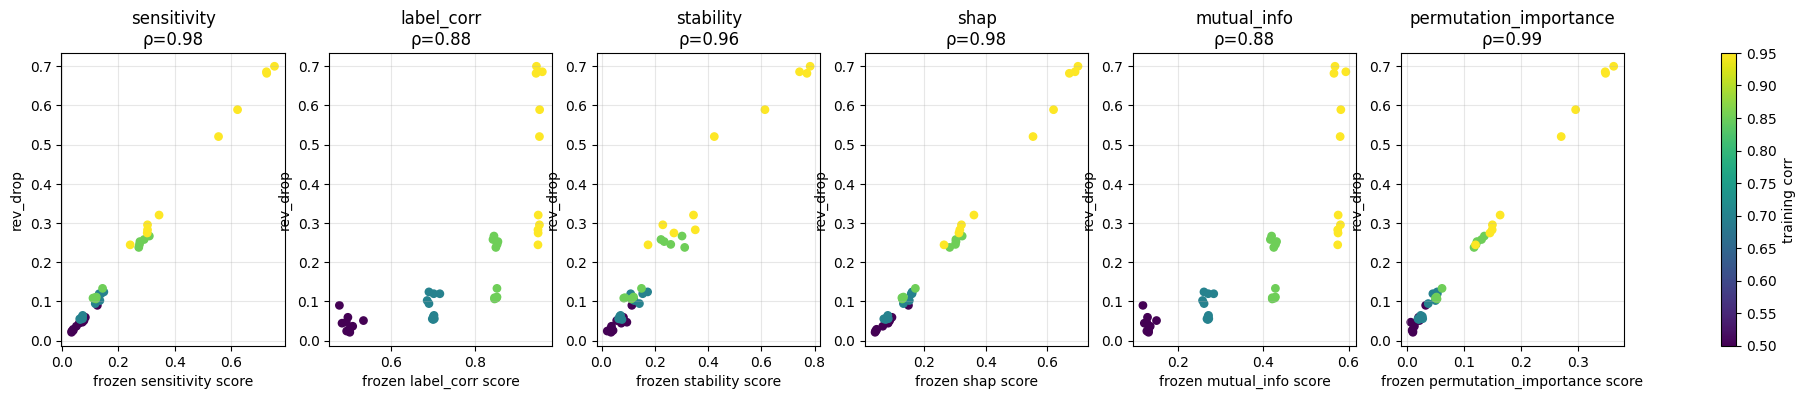

In [14]:
def ood_and_analyze(c, plot=True):
    core.verify_freeze(c)
    p = core.paths(c)
    core.ood_evaluate(c)
    core.analyze(c, target="mean_drop", plot=False)
    shutil.copy(p["analysis"], f"{p['dir']}/analysis_spearman_mean_drop.csv")
    out = core.analyze(c, plot=plot)
    shutil.copy(p["analysis"], f"{p['dir']}/analysis_spearman_{c['target']}.csv")
    return out

if SETTINGS["run_ood_after_freeze"]:
    core.verify_freeze(cfg)
    if SETTINGS["sweep"]:
        core.verify_freeze(cfg_sweep)
    core.load_data(include_test=True)            # OOD data enters only now
    results, controls, blind, mixed = ood_and_analyze(cfg)
else:
    print("Skipped (SETTINGS['run_ood_after_freeze'] is False).")

### Within-level analysis

Pooled Spearman is driven largely by the training correlation, which label correlation also tracks. The stronger test holds the training correlation fixed: within each level, does the frozen score still rank the runs by their later OOD drop? Each level has 10 runs (2 sizes × 5 seeds), so part of the within-level signal is the size effect from Part 4. The `within_corr_and_size` column goes one step further (5 seeds per cell, so it is noisy).

In [15]:
def within_level(c, target):
    _, df = core.load_analysis_table(c)
    def rho(d, m):
        d = d[[m, target]].dropna()
        return spearmanr(d[m], d[target])[0] if d[m].nunique() > 1 and d[target].nunique() > 1 else np.nan
    t = pd.DataFrame({corr: {m: rho(d, m) for m in c["methods"]} for corr, d in df.groupby("corr")})
    t["mean_rho"] = t.mean(axis=1)
    t["within_corr_and_size"] = [np.nanmean([rho(d, m) for _, d in df.groupby(["corr", "size"])])
                                 for m in t.index]
    t.index.name = "method"
    return t.sort_values("mean_rho", ascending=False).round(3)

if SETTINGS["run_ood_after_freeze"]:
    wl = []
    for target in ["rev_drop", "mean_drop"]:
        t = within_level(cfg, target)
        print(f"\n=== Within-level Spearman, frozen colour score vs {target} ===")
        print(t.to_string())
        wl.append(t.assign(target=target))
    pd.concat(wl).to_csv(f"{RESULTS_DIR}/within_level_spearman_mlp.csv")


=== Within-level Spearman, frozen colour score vs rev_drop ===
                          0.5    0.7   0.85   0.95  mean_rho  within_corr_and_size
method                                                                            
sensitivity             0.997  0.964  0.964  0.985     0.977                 0.906
shap                    1.000  0.952  0.952  1.000     0.976                 0.900
permutation_importance  0.644  0.879  0.927  0.988     0.860                 0.675
stability               0.855  0.818  0.794  0.927     0.848                 0.375
label_corr             -0.345 -0.127 -0.079  0.115    -0.109                 0.238
mutual_info            -0.345 -0.127 -0.079  0.091    -0.115                 0.238

=== Within-level Spearman, frozen colour score vs mean_drop ===
                          0.5    0.7   0.85   0.95  mean_rho  within_corr_and_size
method                                                                            
shap                    0.915  0.939  0.9

### Sweep results

Does the frozen colour sensitivity predict OOD drop across regularization and augmentation settings, and does colour randomisation remove both the reliance and the drop?

In [16]:
if SETTINGS["run_ood_after_freeze"] and SETTINGS["sweep"]:
    sweep_results = ood_and_analyze(cfg_sweep, plot=False)
    p = core.paths(cfg_sweep)
    sens = core.read_scores(p["frozen"])
    sens = sens[(sens.method == "sensitivity") & (sens.feature == "color")][["run_id", "score"]]
    ood_sw = pd.read_csv(p["ood_wide"]).merge(sens, on="run_id")
    sweep_table = (ood_sw.groupby(["corr", "aug", "reg"])[["score", "rev_drop", "mean_drop", "id_test_acc"]]
                   .mean().rename(columns={"score": "colour_sensitivity"}).round(4))
    sweep_table.to_csv(f"{RESULTS_DIR}/sweep_summary_mlp.csv")
    print("\nSweep: colour sensitivity (frozen) next to the later OOD drop")
    print(sweep_table)

OOD evaluation done for 60 runs -> /kaggle/working/results/mlp/runs_mlp_sweep/ood_drops.csv


/kaggle/working/core.py:602: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)



=== Score vs mean_drop (feature = color) ===
                method  n  spearman  ci_lo  ci_hi   p  partial_rho|label_corr  partial_p  p_holm  partial_p_holm
           sensitivity 60    0.8735 0.7945 0.9612 0.0                  0.5934     0.0000     0.0          0.0000
            label_corr 60    0.8777 0.7939 0.9582 0.0                     NaN        NaN     0.0             NaN
             stability 60    0.9010 0.8396 0.9695 0.0                  0.5765     0.0000     0.0          0.0000
                  shap 60    0.8354 0.7746 0.9182 0.0                  0.4000     0.0017     0.0          0.0017
           mutual_info 60    0.8777 0.7939 0.9582 0.0                     NaN        NaN     0.0             NaN
permutation_importance 60    0.9694 0.9324 0.9919 0.0                  0.8624     0.0000     0.0          0.0000

=== Mixed-effects model ===
                 Coef. Std.Err.        z  P>|z|  [0.025  0.975]
Intercept       0.051    0.001   46.154  0.000   0.049   0.053
sensiti

/kaggle/working/core.py:602: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)


## Part 9: hard blind detection

The 10-task blind detection saturates (every method is perfect for LR and CNN). This version is harder in two ways: the two shortcuts get **close** random strengths (stronger one 0.75 to 0.90, the other up to 0.10 below it), plus one label-independent decoy; and the ground truth is not the designed strength but **what actually hurts**: after the scores are computed, each attribute is reversed on test digits one at a time, and the attribute whose reversal costs the most accuracy is the true worst shortcut.

Order inside every task: train on E1 → compute all six scores on E1 validation → only then evaluate the reversals. Reported per method: top-1 (ranks the most harmful attribute first), strong-vs-weak order (ranks the two shortcuts in the order of their actual damage), and AUROC of shortcut vs decoy. Output: `hard_blind_detection_mlp.csv`.

In [17]:
def run_hard_task(task_id, size=5000, n_score=1000):
    rng = np.random.default_rng(5000 + task_id)
    order = list(rng.permutation(core.ATTRS))
    strong = round(float(rng.uniform(0.75, 0.90)), 3)
    weak = round(strong - float(rng.uniform(0.0, 0.10)), 3)
    corrs = {order[0]: strong, order[1]: weak, order[2]: 0.0}
    role = {order[0]: "strong", order[1]: "weak", order[2]: "decoy"}

    idx = rng.choice(len(core.train_y), size=size, replace=False)
    Xtr, Atr = core.make_multi_attr_mnist(core.train_x[idx], core.train_y[idx], corrs, seed=6000 + task_id)
    ytr = core.train_y[idx]
    Xva, Ava = core.make_multi_attr_mnist(core.val_x, core.val_y, corrs, seed=7000 + task_id)
    model = core.make_model("mlp", "default", task_id).fit(core.flat(Xtr), ytr)

    # 1) pre-shift scores, E1 only
    ctx = {"model": model, "Xs": Xva[:n_score], "ys": core.val_y[:n_score],
           "As": {a: v[:n_score] for a, v in Ava.items()}, "Atr": Atr, "ytr": ytr}
    pre = {(m, a): core.SCORE_FNS[m](ctx, a) for m in cfg["methods"] for a in core.ATTRS}

    # 2) ground truth afterwards: reverse one attribute at a time on the same test digits
    Xb, _ = core.make_multi_attr_mnist(core.test_x, core.test_y, corrs, seed=8000 + task_id)
    base = accuracy_score(core.test_y, model.predict(core.flat(Xb)))
    rows = []
    for a in core.ATTRS:
        Xr, _ = core.make_multi_attr_mnist(core.test_x, core.test_y, {**corrs, a: -corrs[a]}, seed=8000 + task_id)
        drop = base - accuracy_score(core.test_y, model.predict(core.flat(Xr)))
        rows.append({"task": task_id, "attr": a, "role": role[a], "true_corr": corrs[a],
                     "observed_corr": float(np.corrcoef(ytr, Atr[a])[0, 1]),
                     "actual_drop": drop, **{m: pre[(m, a)] for m in cfg["methods"]}})
    return rows

def summarize_hard(df, methods):
    out = {}
    for m in methods:
        top1, order_ok = [], []
        for _, d in df.groupby("task"):
            top1.append(d.loc[d[m].idxmax(), "attr"] == d.loc[d["actual_drop"].idxmax(), "attr"])
            s, w = d[d.role == "strong"].iloc[0], d[d.role == "weak"].iloc[0]
            order_ok.append((s[m] > w[m]) == (s["actual_drop"] > w["actual_drop"]))
        out[m] = {"top1_most_harmful": np.mean(top1), "strong_vs_weak_order": np.mean(order_ok),
                  "auroc_shortcut_vs_decoy": roc_auc_score(df.role != "decoy", df[m].fillna(df[m].min()))}
    return pd.DataFrame(out).T.sort_values("top1_most_harmful", ascending=False).round(3)

if SETTINGS["run_ood_after_freeze"]:
    hard_rows = []
    for t in range(SETTINGS["hard_tasks"]):
        t0 = time.time()
        r = run_hard_task(t)
        hard_rows += r
        worst = max(r, key=lambda x: x["actual_drop"])
        print(f"task {t:2d} " + ", ".join(f"{x['attr']}={x['true_corr']}" for x in r)
              + f"  -> most harmful: {worst['attr']} ({worst['role']}, drop {worst['actual_drop']:.3f})"
              + f"  ({time.time() - t0:.0f}s)")
    hard_df = pd.DataFrame(hard_rows)
    hard_df.to_csv(f"{RESULTS_DIR}/hard_blind_detection_mlp.csv", index=False)
    worst_roles = hard_df.loc[hard_df.groupby("task")["actual_drop"].idxmax(), "role"].value_counts()
    print("\nRole of the most harmful attribute:", worst_roles.to_dict())
    hard_summary = summarize_hard(hard_df, cfg["methods"])
    hard_summary.to_csv(f"{RESULTS_DIR}/hard_blind_detection_summary_mlp.csv")
    print(f"\nHard blind detection, MLP, {SETTINGS['hard_tasks']} tasks")
    print(hard_summary)

task  0 color=0.803, marker_tl=0.723, marker_br=0.0  -> most harmful: color (strong, drop 0.148)  (13s)
task  1 color=0.702, marker_tl=0.0, marker_br=0.76  -> most harmful: marker_br (strong, drop 0.094)  (14s)
task  2 color=0.865, marker_tl=0.839, marker_br=0.0  -> most harmful: color (strong, drop 0.153)  (11s)
task  3 color=0.769, marker_tl=0.0, marker_br=0.719  -> most harmful: color (strong, drop 0.082)  (13s)
task  4 color=0.805, marker_tl=0.821, marker_br=0.0  -> most harmful: marker_tl (strong, drop 0.145)  (10s)
task  5 color=0.0, marker_tl=0.804, marker_br=0.83  -> most harmful: marker_br (strong, drop 0.106)  (12s)
task  6 color=0.817, marker_tl=0.0, marker_br=0.768  -> most harmful: color (strong, drop 0.118)  (20s)
task  7 color=0.834, marker_tl=0.828, marker_br=0.0  -> most harmful: marker_tl (weak, drop 0.113)  (14s)
task  8 color=0.779, marker_tl=0.0, marker_br=0.704  -> most harmful: color (strong, drop 0.102)  (12s)
task  9 color=0.0, marker_tl=0.851, marker_br=0.789 

## Part 10: hand-off

Everything is under `/kaggle/working/results/mlp/`, laid out like `results/lr` and `results/cnn`:

- `runs_mlp/`: `scores_frozen.csv` (read-only) + `scores_frozen.manifest.json`, `run_meta.csv`, `ood_drops.csv`, `ood_drops_long.csv`, `analysis_spearman.csv` and the `analysis_spearman_<target>.csv` copies, `models/` (MLPs unpickle with plain scikit-learn, no wrapper file needed)
- `runs_mlp_sweep/`: the same files for the regularization × augmentation sweep
- `blind_detection_mlp.csv`, `hard_blind_detection_mlp.csv` (+ `_summary`)
- `realism_check_mlp.csv`, `reg_check_mlp.csv`
- `within_level_spearman_mlp.csv`, `colour_scores_by_size_mlp.csv`, `sweep_colour_scores_mlp.csv`, `sweep_summary_mlp.csv`
- `weight_regions_mlp.csv` (exploratory)
- `core.sha256` (must match the other model notebooks)

For GitHub, `results_mlp_github.zip` holds everything **except** `models/` and `partial/` (the repo does not commit model files).

In [18]:
for root, _, files in sorted(os.walk(RESULTS_DIR)):
    rel = os.path.relpath(root, RESULTS_DIR)
    if rel.endswith("models") or rel.endswith("partial"):
        print(f"{rel}/  ({len(files)} files)"); continue
    for f in sorted(files):
        print(f if rel == "." else f"{rel}/{f}")

zip_path = f"{core.WORK}/results_mlp_github.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(RESULTS_DIR):
        if os.sep + "models" in root or os.sep + "partial" in root:
            continue
        for f in files:
            full = os.path.join(root, f)
            z.write(full, os.path.join("results", "mlp", os.path.relpath(full, RESULTS_DIR)))
print("\nWrote", zip_path, f"({os.path.getsize(zip_path) / 1e6:.2f} MB)")

blind_detection_mlp.csv
colour_scores_by_size_mlp.csv
core.sha256
hard_blind_detection_mlp.csv
hard_blind_detection_summary_mlp.csv
realism_check_mlp.csv
reg_check_mlp.csv
sweep_colour_scores_mlp.csv
sweep_summary_mlp.csv
weight_regions_mlp.csv
within_level_spearman_mlp.csv
runs_mlp/analysis_spearman.csv
runs_mlp/analysis_spearman_mean_drop.csv
runs_mlp/analysis_spearman_rev_drop.csv
runs_mlp/ood_drops.csv
runs_mlp/ood_drops_long.csv
runs_mlp/run_meta.csv
runs_mlp/scores_frozen.csv
runs_mlp/scores_frozen.manifest.json
runs_mlp/models/  (40 files)
runs_mlp/partial/  (80 files)
runs_mlp_sweep/analysis_spearman.csv
runs_mlp_sweep/analysis_spearman_mean_drop.csv
runs_mlp_sweep/analysis_spearman_rev_drop.csv
runs_mlp_sweep/ood_drops.csv
runs_mlp_sweep/ood_drops_long.csv
runs_mlp_sweep/run_meta.csv
runs_mlp_sweep/scores_frozen.csv
runs_mlp_sweep/scores_frozen.manifest.json
runs_mlp_sweep/models/  (60 files)
runs_mlp_sweep/partial/  (120 files)

Wrote /kaggle/working/results_mlp_github.zip (0